# 00 · Exploratory Data Analysis (EDA)
Explore the cleaned SkinMatch dataset (`skincare_clean.csv`, created by `preprocessing.ipynb`) with summary
statistics and visualisations: histograms, boxplots, scatterplots and count/bar plots.

In [1]:
# Load the cleaned dataset and check shape, columns and datatypes.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("skincare_clean.csv")
COLORS = ['#95A792', '#C98A97', '#6F8569', '#E6C3A1', '#7A9CC6', '#B5A1C9', '#D9A066']
skin_cols = ["tag_dry", "tag_oily", "tag_combination", "tag_normal", "tag_sensitive", "tag_acne_prone"]
flag_cols = ["has_niacinamide", "has_salicylic_acid", "has_zinc", "has_clay", "has_heavy_oil_butter",
             "has_ceramide", "has_hyaluronic", "has_squalane", "has_fragrance", "has_alcohol_denat",
             "has_essential_oil", "oil_free"]

print("Shape:", df.shape)
df.info()

Shape: (2724, 37)
<class 'pandas.DataFrame'>
RangeIndex: 2724 entries, 0 to 2723
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   brand                 2724 non-null   str    
 1   name                  2724 non-null   str    
 2   category              2724 non-null   str    
 3   ingredients_clean     2724 non-null   str    
 4   ingredient_count      2724 non-null   int64  
 5   price_usd             2724 non-null   float64
 6   price_pkr             2724 non-null   float64
 7   price_capped          2724 non-null   float64
 8   tag_dry               1557 non-null   float64
 9   tag_oily              1557 non-null   float64
 10  tag_combination       1557 non-null   float64
 11  tag_normal            1557 non-null   float64
 12  tag_sensitive         1557 non-null   float64
 13  tag_acne_prone        1557 non-null   float64
 14  n_tags                2724 non-null   int64  
 15  specificity   

## 1. Summary statistics

In [2]:
# Numerical columns.
display(df[["price_usd", "price_pkr", "ingredient_count", "n_tags", "specificity"]].describe().round(2))

,price_usd,price_pkr,ingredient_count,n_tags,specificity
count,2724.00,2724.00,2724.00,2724.00,1557.00
mean,57.70,15993.26,33.89,1.98,0.41
std,50.22,13920.60,15.54,2.06,0.30
min,3.00,832.00,3.00,0.00,0.17
25%,30.00,8315.00,23.00,0.00,0.20
50%,45.00,12473.00,32.00,1.00,0.25
75%,69.00,19125.00,43.00,4.00,0.33
max,449.00,124449.00,98.00,6.00,1.00


In [3]:
# Categorical columns: number of unique values and the most common value.
cat_cols = ["brand", "category", "source", "helps_with_source"]
summary = pd.DataFrame({"Unique values": df[cat_cols].nunique(),
                        "Most common": [df[c].mode()[0] for c in cat_cols],
                        "Count of most common": [df[c].value_counts().iloc[0] for c in cat_cols]})
display(summary)
print("Products with a skin-type label:", int(df["has_skin_label"].sum()), "of", len(df))
print("Missing values in model columns:", int(df[["ingredients_clean", "category", "price_usd"]].isna().sum().sum()))

,Unique values,Most common,Count of most common
brand,174,Clinique,113
category,7,Moisturizer,588
source,4,kaggle (sephora 2023),1632
helps_with_source,2,derived,1428


Products with a skin-type label: 1557 of 2724
Missing values in model columns: 0


In [4]:
# Average price and number of ingredients per category.
display(df.groupby("category").agg(products=("name", "count"),
                                   median_price_usd=("price_usd", "median"),
                                   mean_price_usd=("price_usd", "mean"),
                                   median_ingredients=("ingredient_count", "median")).round(1)
          .sort_values("products", ascending=False))

,products,median_price_usd,mean_price_usd,median_ingredients
category,,,,
Moisturizer,588,54.0,71.0,40.0
Treatment,492,49.0,62.8,26.5
Cleanser,406,30.0,33.4,26.0
Serum,364,62.0,72.7,31.0
Mask,337,38.0,43.0,30.0
Eye care,320,56.5,64.5,41.0
Sun protection,217,37.0,43.4,32.0


## 2. Histograms: distribution of numerical features

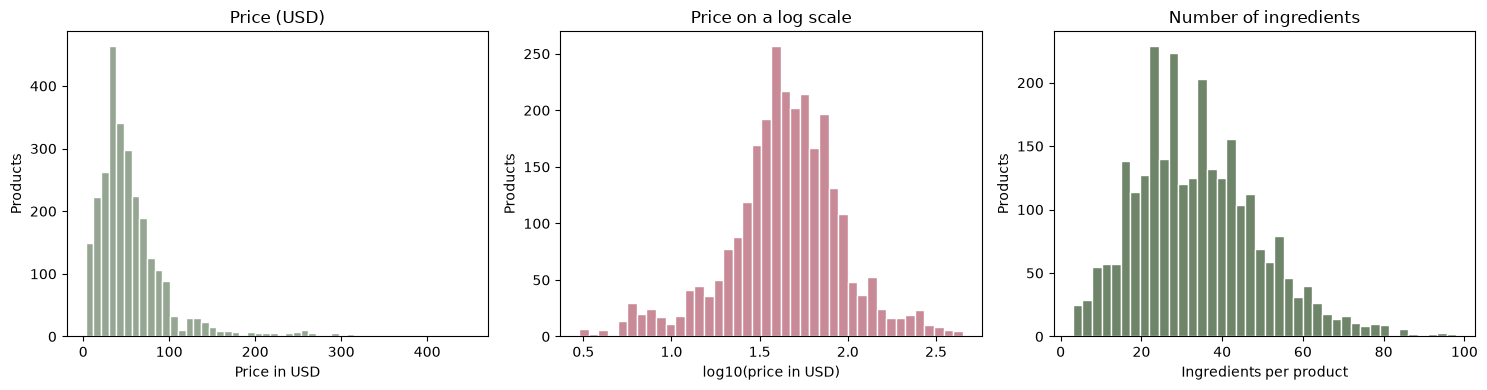

Price skewness: 3.16 | log-price skewness: -0.36


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["price_usd"], bins=50, color=COLORS[0], edgecolor="white")
axes[0].set_title("Price (USD)")
axes[0].set_xlabel("Price in USD")
axes[1].hist(np.log10(df["price_usd"]), bins=40, color=COLORS[1], edgecolor="white")
axes[1].set_title("Price on a log scale")
axes[1].set_xlabel("log10(price in USD)")
axes[2].hist(df["ingredient_count"], bins=40, color=COLORS[2], edgecolor="white")
axes[2].set_title("Number of ingredients")
axes[2].set_xlabel("Ingredients per product")
for ax in axes:
    ax.set_ylabel("Products")
plt.tight_layout()
plt.show()
print("Price skewness:", round(df["price_usd"].skew(), 2),
      "| log-price skewness:", round(np.log10(df["price_usd"]).skew(), 2))

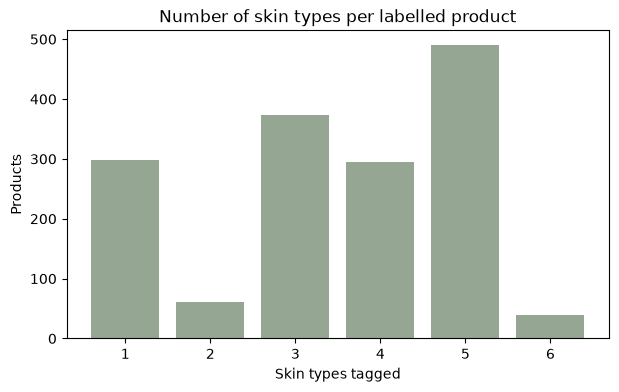

Tagged for all five main skin types: 519 (33% of labelled products)


In [6]:
# How many skin types each labelled product is tagged for.
labelled = df[df["has_skin_label"] == 1]
counts = labelled["n_tags"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(counts.index.astype(str), counts.values, color=COLORS[0])
plt.title("Number of skin types per labelled product")
plt.xlabel("Skin types tagged")
plt.ylabel("Products")
plt.show()
print(f"Tagged for all five main skin types: {int(labelled['is_general'].sum())} "
      f"({labelled['is_general'].mean():.0%} of labelled products)")

## 3. Boxplots: detecting outliers

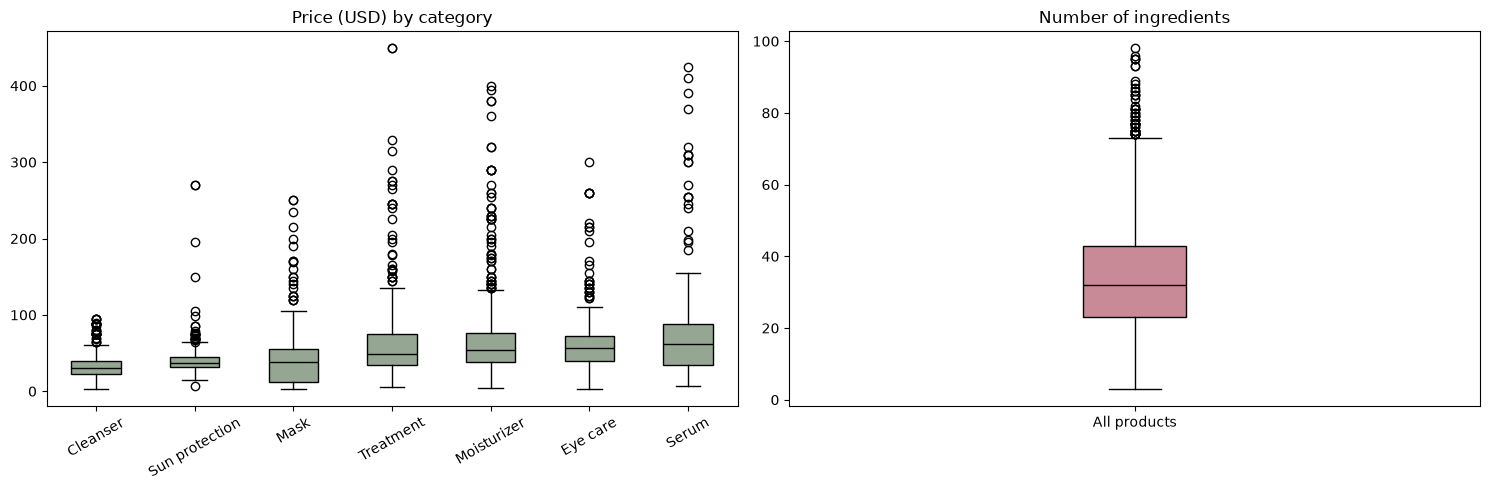

In [7]:
order = df.groupby("category")["price_usd"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].boxplot([df.loc[df["category"] == c, "price_usd"] for c in order], patch_artist=True,
                boxprops=dict(facecolor=COLORS[0]), medianprops=dict(color="black"))
axes[0].set_xticks(range(1, len(order) + 1))
axes[0].set_xticklabels(order)
axes[0].set_title("Price (USD) by category")
axes[0].tick_params(axis="x", rotation=30)
axes[1].boxplot([df["ingredient_count"]], patch_artist=True,
                boxprops=dict(facecolor=COLORS[1]), medianprops=dict(color="black"))
axes[1].set_xticks([1])
axes[1].set_xticklabels(["All products"])
axes[1].set_title("Number of ingredients")
plt.tight_layout()
plt.show()

In [8]:
# Count outliers with the IQR rule (below Q1 - 1.5*IQR or above Q3 + 1.5*IQR).
for col in ["price_usd", "ingredient_count"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: normal range {max(low, 0):.0f} - {high:.0f} | outliers: {n} ({n / len(df):.1%})")
print("\nMost expensive products (kept: real luxury items; price_capped limits the top 1%):")
display(df.nlargest(5, "price_usd")[["brand", "name", "category", "price_usd"]])

price_usd: normal range 0 - 128 | outliers: 180 (6.6%)
ingredient_count: normal range 0 - 73 | outliers: 51 (1.9%)

Most expensive products (kept: real luxury items; price_capped limits the top 1%):


,brand,name,category,price_usd
1140,NuFACE,Trinity + Eye and Lip Enhancer Attachment Bundle,Treatment,449.0
1142,NuFACE,Trinity Facial Toning Device + Wrinkle Reducer...,Treatment,449.0
965,La Mer,The Concentrate Serum,Serum,425.0
970,La Mer,The Regenerating Serum,Serum,410.0
1442,Sk-Ii,Ultimate Revival Cream,Moisturizer,400.0


## 4. Scatterplots: trends between variables

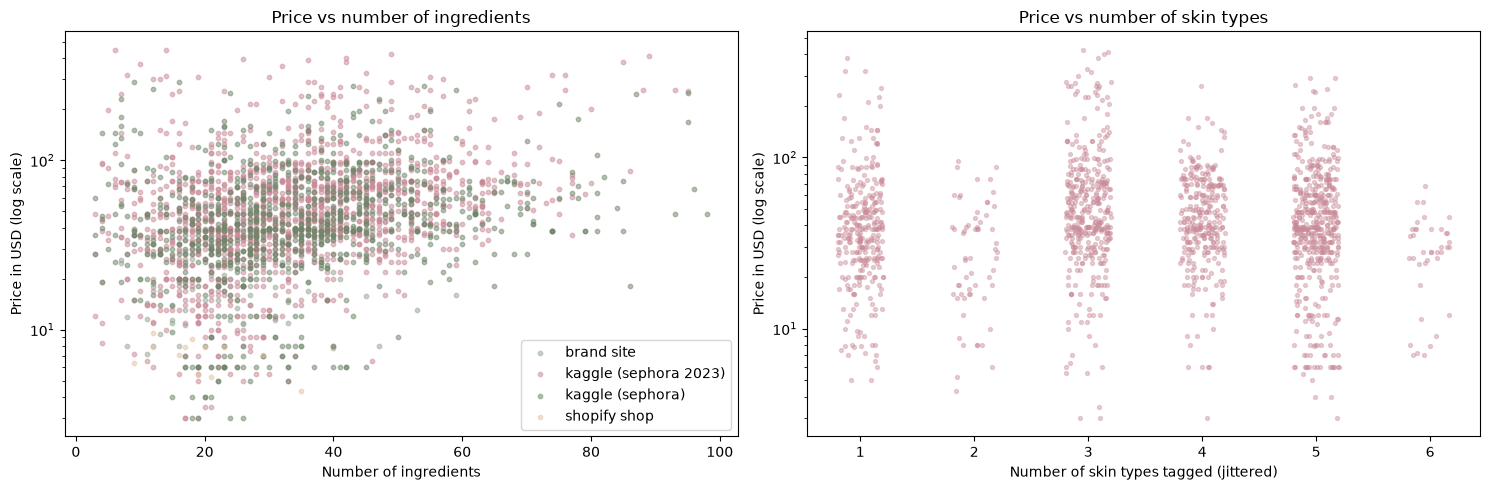

Correlation price vs ingredient count: 0.234
Spearman (rank) correlation: 0.339


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, (src, grp) in enumerate(df.groupby("source")):
    axes[0].scatter(grp["ingredient_count"], grp["price_usd"], s=10, alpha=0.5, label=src, color=COLORS[i])
axes[0].set_yscale("log")
axes[0].set_xlabel("Number of ingredients")
axes[0].set_ylabel("Price in USD (log scale)")
axes[0].set_title("Price vs number of ingredients")
axes[0].legend()

axes[1].scatter(labelled["n_tags"] + np.random.uniform(-0.2, 0.2, len(labelled)), labelled["price_usd"],
                s=8, alpha=0.4, color=COLORS[1])
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of skin types tagged (jittered)")
axes[1].set_ylabel("Price in USD (log scale)")
axes[1].set_title("Price vs number of skin types")
plt.tight_layout()
plt.show()
print("Correlation price vs ingredient count:", round(df["price_usd"].corr(df["ingredient_count"]), 3))
print("Spearman (rank) correlation:", round(df["price_usd"].corr(df["ingredient_count"], method="spearman"), 3))

## 5. Count and bar plots: categorical values

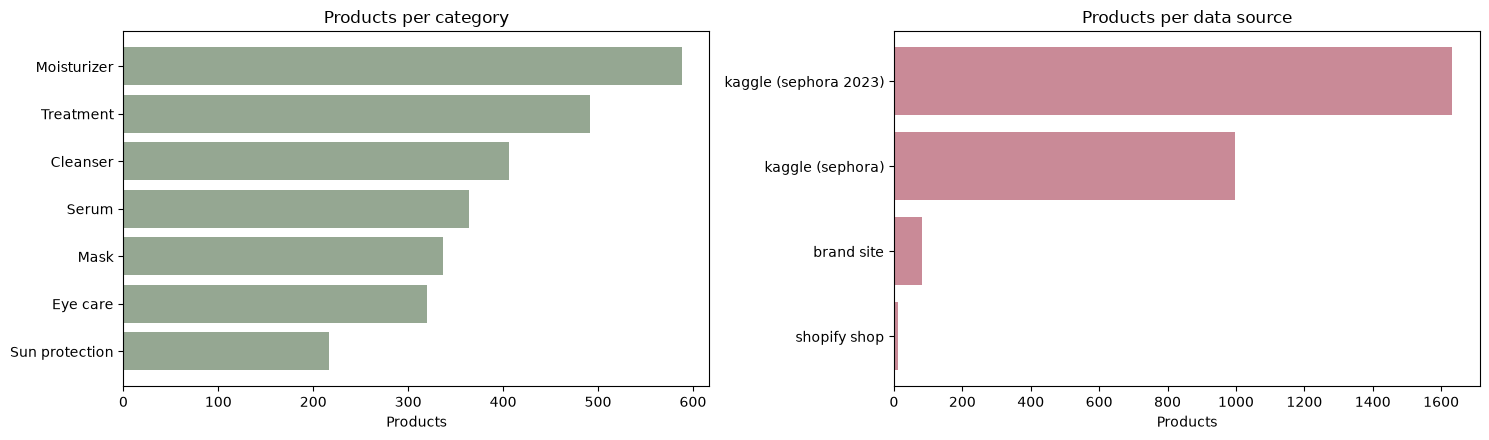

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
cat = df["category"].value_counts()
axes[0].barh(cat.index[::-1], cat.values[::-1], color=COLORS[0])
axes[0].set_title("Products per category")
src = df["source"].value_counts()
axes[1].barh(src.index[::-1], src.values[::-1], color=COLORS[1])
axes[1].set_title("Products per data source")
for ax in axes:
    ax.set_xlabel("Products")
plt.tight_layout()
plt.show()

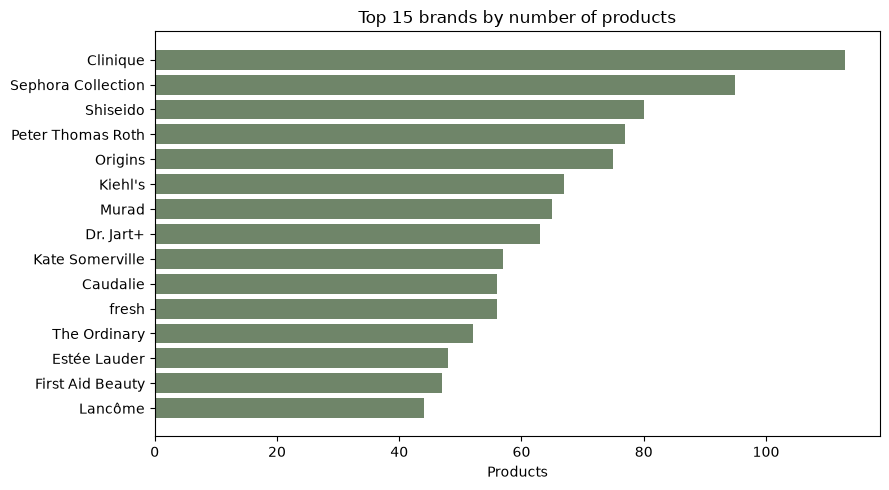

In [11]:
top_brands = df["brand"].value_counts().head(15)
plt.figure(figsize=(9, 5))
plt.barh(top_brands.index[::-1], top_brands.values[::-1], color=COLORS[2])
plt.title("Top 15 brands by number of products")
plt.xlabel("Products")
plt.tight_layout()
plt.show()

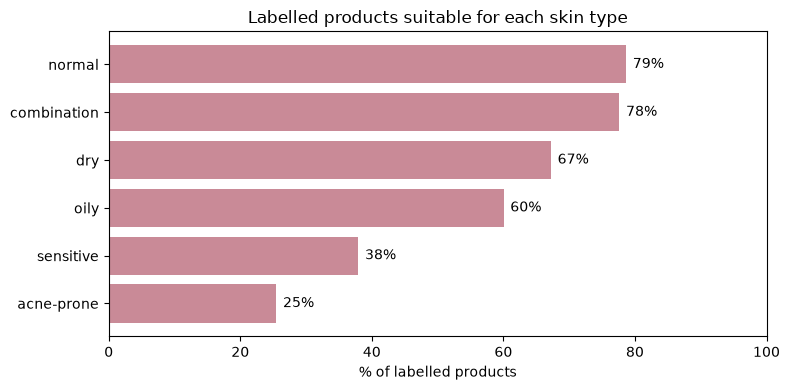

Labelled: 1557 | unlabelled (to be predicted): 1167


In [12]:
# Skin-type labels: share of labelled products tagged for each skin type (shows the class imbalance).
share = (labelled[skin_cols].mean() * 100).sort_values()
plt.figure(figsize=(8, 4))
plt.barh([s.replace("tag_", "").replace("_", "-") for s in share.index], share.values, color=COLORS[1])
plt.title("Labelled products suitable for each skin type")
plt.xlabel("% of labelled products")
for y, v in enumerate(share.values):
    plt.text(v + 1, y, f"{v:.0f}%", va="center")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()
print("Labelled:", len(labelled), "| unlabelled (to be predicted):", int((df["has_skin_label"] == 0).sum()))

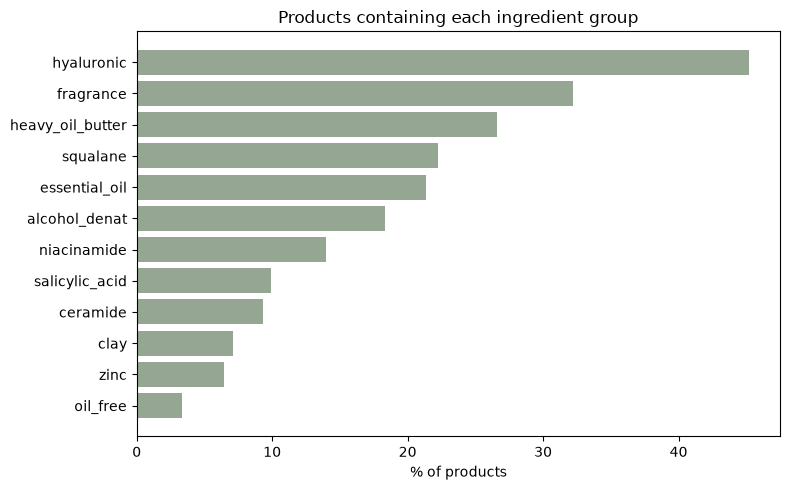

In [13]:
# How common each ingredient flag is.
flags = (df[flag_cols].mean() * 100).sort_values()
plt.figure(figsize=(8, 5))
plt.barh([f.replace("has_", "") for f in flags.index], flags.values, color=COLORS[0])
plt.title("Products containing each ingredient group")
plt.xlabel("% of products")
plt.tight_layout()
plt.show()

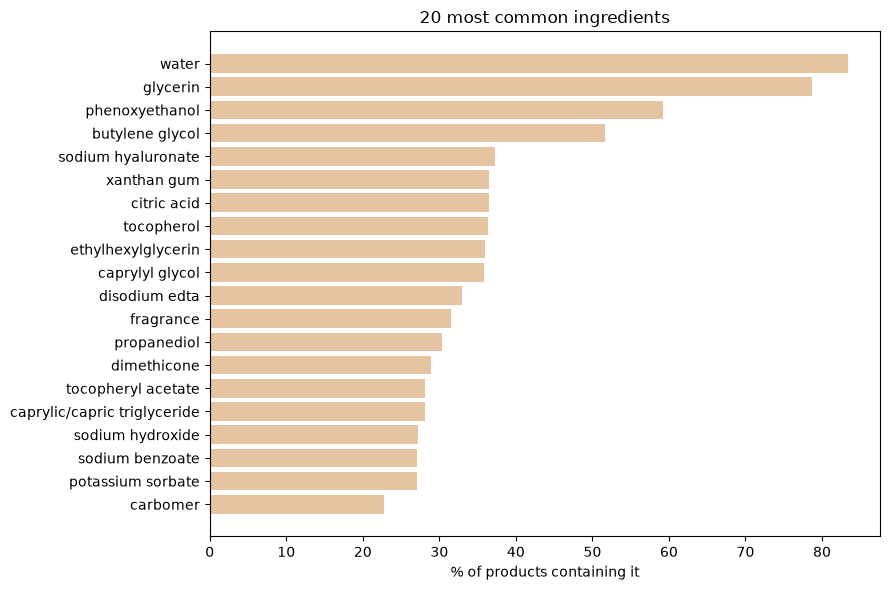

Unique ingredients: 7316 | appearing in only one product: 3619


In [14]:
# The 20 most common ingredients.
ingredients = df["ingredients_clean"].str.split("|").explode()
top = ingredients.value_counts().head(20)
plt.figure(figsize=(9, 6))
plt.barh(top.index[::-1], (top.values[::-1] / len(df) * 100), color=COLORS[3])
plt.title("20 most common ingredients")
plt.xlabel("% of products containing it")
plt.tight_layout()
plt.show()
print("Unique ingredients:", ingredients.nunique(), "| appearing in only one product:",
      int((ingredients.value_counts() == 1).sum()))

In [15]:
# Which ingredients are more common in products for each skin type? (labelled products only)
table = pd.DataFrame({s.replace("tag_", ""): labelled.loc[labelled[s] == 1, flag_cols].mean() * 100
                      for s in skin_cols})
table["all labelled"] = labelled[flag_cols].mean() * 100
display(table.round(0).astype(int))

,dry,oily,combination,normal,sensitive,acne_prone,all labelled
has_niacinamide,13,15,13,14,14,18,15
has_salicylic_acid,7,13,11,11,6,33,14
has_zinc,6,7,7,6,6,13,8
has_clay,7,11,9,9,9,22,10
has_heavy_oil_butter,28,21,24,24,26,8,23
has_ceramide,12,8,9,10,8,6,10
has_hyaluronic,45,39,42,42,41,30,42
has_squalane,24,17,21,22,21,10,21
has_fragrance,36,32,35,34,31,21,32
has_alcohol_denat,19,22,21,20,21,22,20


### Conclusion

- **Data:** 2,724 products across 7 categories and 174 brands, with no missing values in the columns used by
  the models. 1,557 products have skin-type labels; 1,167 do not and are predicted by the classifier.
- **Prices** are strongly right-skewed (skewness 3.2): the median is $45 and half of all products cost $30–$69,
  with a long tail up to $449. The IQR rule flags 180 products (6.6%) above $128 as outliers. They are real
  luxury products (e.g. La Mer, SK-II), so they were kept, and the top 1% was capped in `price_capped`. On a log
  scale the distribution is close to symmetric (skewness −0.4).
- **Ingredients:** the median product has 32 ingredients; 51 products (1.9%) have unusually long lists.
  Water, glycerin and phenoxyethanol appear in most products, while 3,619 of the 7,316 distinct ingredients
  appear in only one product. This motivates **TF-IDF**, which down-weights common ingredients and highlights
  distinctive ones.
- **Price vs ingredients:** only a weak positive relationship (correlation 0.23, rank correlation 0.34);
  longer ingredient lists do not mean much higher prices.
- **Skin-type labels are imbalanced:** most labelled products suit normal (79%) and combination (78%) skin,
  but only 38% suit sensitive and 25% acne-prone skin, and a third of labelled products are tagged for all five
  main types. This is why the classifiers are evaluated with **macro F1** and use **balanced class weights**.
- **Ingredients differ clearly for acne-prone products:** they contain salicylic acid (33% vs 14% overall),
  clay (22% vs 10%) and oil-free formulas (12% vs 4%) more often, and heavy oils/butters less often (8% vs 23%).
  For sensitive skin there is **no clear difference** (fragrance 31% vs 32% overall), which suggests retailers'
  "sensitive" tags are broad and explains why sensitive skin is the hardest label to predict.